# Benchmark Hugging Face: sentimientos IMDb
Tres modelos SST-2 sobre IMDb, métricas y latencia.

In [ ]:
!pip -q install "torch>=2.2,<3" "transformers>=4.44,<5" "datasets>=3,<5" "scikit-learn>=1.4,<2" "pandas>=2,<3" "huggingface_hub>=0.25,<2" "accelerate>=0.33,<2"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 40.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 51.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os,sys,json,platform,torch,transformers,datasets,pandas as pd
from pathlib import Path
ROOT=Path('/content/hf_sentiment_project'); ROOT.mkdir(exist_ok=True)
(ROOT/'results').mkdir(exist_ok=True); (ROOT/'data').mkdir(exist_ok=True)
print('GPU disponible:',torch.cuda.is_available())
if torch.cuda.is_available(): print('GPU:',torch.cuda.get_device_name(0))
else: print('AVISO: ejecutar con GPU para comparar latencia en GPU')


GPU disponible: True
GPU: Tesla T4


In [3]:
try:
    from google.colab import userdata
    token=userdata.get('HF_TOKEN')
    if token:
        from huggingface_hub import login
        login(token=token,add_to_git_credential=False)
        print('Autenticación realizada')
    else: print('Acceso público sin autenticación')
except Exception as e:
    print('Acceso público sin autenticación:',type(e).__name__)


Acceso público sin autenticación: SecretNotFoundError


## Dataset
IMDb: `text` reseña en inglés; `label` 0 negativo, 1 positivo. Muestra estratificada 300 ejemplos, seed 42.


In [4]:
from datasets import load_dataset
raw=load_dataset('stanfordnlp/imdb',split='test')
neg=raw.filter(lambda x:x['label']==0).shuffle(seed=42).select(range(150))
pos=raw.filter(lambda x:x['label']==1).shuffle(seed=42).select(range(150))
frame=pd.concat([neg.to_pandas(),pos.to_pandas()],ignore_index=True).sample(frac=1,random_state=42).reset_index(drop=True)
frame.to_csv(ROOT/'data/imdb_sample.csv',index=False)
print(frame['label'].value_counts()); display(frame[['text','label']].head())


label
1    150
0    150
Name: count, dtype: int64


,text,label
0,"A brash, self-centered Army cadet arrives at W...",1
1,I stumbled across this film while channel surf...,1
2,"Lets face it, Australian TV is for the most pa...",1
3,Me and a buddy rented this movie the other day...,0
4,Thank goodness for the Coen Brothers. Their su...,1


## Inferencia, medición y métricas
Las etiquetas se alinean con `id2label` del modelo; el código falla explícitamente si la clase positiva no puede identificarse.


In [ ]:
import time, numpy as np, torch
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification

def evaluate(model_id, texts, labels, batch_size=16, max_length=256):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForSequenceClassification.from_pretrained(model_id).to(device).eval()
    # Map model class ids to IMDB convention: negative=0, positive=1.
    id2label = {int(k):str(v).lower() for k,v in model.config.id2label.items()}
    def positive_index():
        for idx,name in id2label.items():
            if name in ('positive','pos','label_1') or 'positive' in name: return idx
        raise ValueError(f'Cannot verify positive label mapping for {model_id}: {id2label}')
    pos_idx=positive_index()
    def predict(batch):
        inputs=tokenizer(batch,padding=True,truncation=True,max_length=max_length,return_tensors='pt').to(device)
        with torch.inference_mode(): logits=model(**inputs).logits
        return (logits.argmax(-1)==pos_idx).long().cpu().tolist()
    # warm-up excluded from measured latency
    predict(texts[:min(batch_size,len(texts))])
    if device.type=='cuda': torch.cuda.synchronize()
    start=time.perf_counter(); predictions=[]
    for i in range(0,len(texts),batch_size): predictions.extend(predict(texts[i:i+batch_size]))
    if device.type=='cuda': torch.cuda.synchronize()
    seconds=time.perf_counter()-start
    precision,recall,f1,_=precision_recall_fscore_support(labels,predictions,average='binary',zero_division=0)
    result={'model':model_id,'accuracy':accuracy_score(labels,predictions),'precision':precision,'recall':recall,'f1':f1,'total_seconds':seconds,'ms_per_review':seconds*1000/len(texts),'reviews_per_second':len(texts)/seconds,'gpu':str(device),'batch_size':batch_size,'max_length':max_length,'n':len(texts),'confusion_matrix':confusion_matrix(labels,predictions,labels=[0,1]).tolist()}
    del model,tokenizer
    if device.type=='cuda': torch.cuda.empty_cache()
    return result

MODELS={'DistilBERT':'distilbert/distilbert-base-uncased-finetuned-sst-2-english','BERT':'textattack/bert-base-uncased-SST-2','RoBERTa':'textattack/roberta-base-SST-2'}
results=[]
for name,model_id in MODELS.items():
    print('Evaluando',name,model_id)
    result=evaluate(model_id,frame['text'].tolist(),frame['label'].tolist(),batch_size=16,max_length=256)
    result['name']=name
    results.append(result)
    print({k:round(result[k],4) for k in ['accuracy','precision','recall','f1','ms_per_review']})


Evaluando DistilBERT distilbert/distilbert-base-uncased-finetuned-sst-2-english


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

...

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/501M [00:00<?, ?B/s]

Some weights of the model checkpoint at textattack/roberta-base-SST-2 were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


{'accuracy': 0.9, 'precision': 0.9478, 'recall': 0.8467, 'f1': 0.8944, 'ms_per_review': 12.1052}


## Comparación y exportación
Accuracy, precision, recall, F1, latencia por reseña, throughput y matrices de confusión.


In [ ]:
table=pd.DataFrame(results).set_index('name')
display(table[['accuracy','precision','recall','f1','ms_per_review','reviews_per_second']].sort_values('f1',ascending=False))
table.reset_index().drop(columns=['confusion_matrix']).to_csv(ROOT/'results/metrics.csv',index=False)
(ROOT/'results/metrics.json').write_text(json.dumps(results,indent=2,default=float))
env={'python':sys.version,'platform':platform.platform(),'torch':torch.__version__,'transformers':transformers.__version__,'datasets':datasets.__version__,'cuda':torch.version.cuda,'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,'seed':42,'sample_size':len(frame),'batch_size':16,'max_length':256,'model_ids':MODELS}
(ROOT/'results/execution_environment.json').write_text(json.dumps(env,indent=2))
print('Archivos:',list((ROOT/'results').iterdir()))


,accuracy,precision,recall,f1,ms_per_review,reviews_per_second
name,,,,,,
RoBERTa,0.900000,0.947761,0.846667,0.894366,12.105169,82.609337
BERT,0.893333,0.909722,0.873333,0.891156,14.595285,68.515276
DistilBERT,0.886667,0.908451,0.860000,0.883562,7.857969,127.259353


Archivos: [PosixPath('/content/hf_sentiment_project/results/metrics.json'), PosixPath('/content/hf_sentiment_project/results/metrics.csv'), PosixPath('/content/hf_sentiment_project/results/execution_environment.json')]


In [ ]:
for result in results:
    print(f"Modelo: {result['name']} ({result['model']})")
    cm = result['confusion_matrix']
    print(f"Verdaderos Negativos (TN): {cm[0][0]} | Falsos Positivos (FP): {cm[0][1]}")
    print(f"Falsos Negativos (FN): {cm[1][0]} | Verdaderos Positivos (VP): {cm[1][1]}")
    print("-" * 50)

Modelo: DistilBERT (distilbert/distilbert-base-uncased-finetuned-sst-2-english)
Verdaderos Negativos (TN): 137 | Falsos Positivos (FP): 13
Falsos Negativos (FN): 21 | Verdaderos Positivos (VP): 129
--------------------------------------------------
Modelo: BERT (textattack/bert-base-uncased-SST-2)
Verdaderos Negativos (TN): 137 | Falsos Positivos (FP): 13
Falsos Negativos (FN): 19 | Verdaderos Positivos (VP): 131
--------------------------------------------------
Modelo: RoBERTa (textattack/roberta-base-SST-2)
Verdaderos Negativos (TN): 143 | Falsos Positivos (FP): 7
Falsos Negativos (FN): 23 | Verdaderos Positivos (VP): 127
--------------------------------------------------


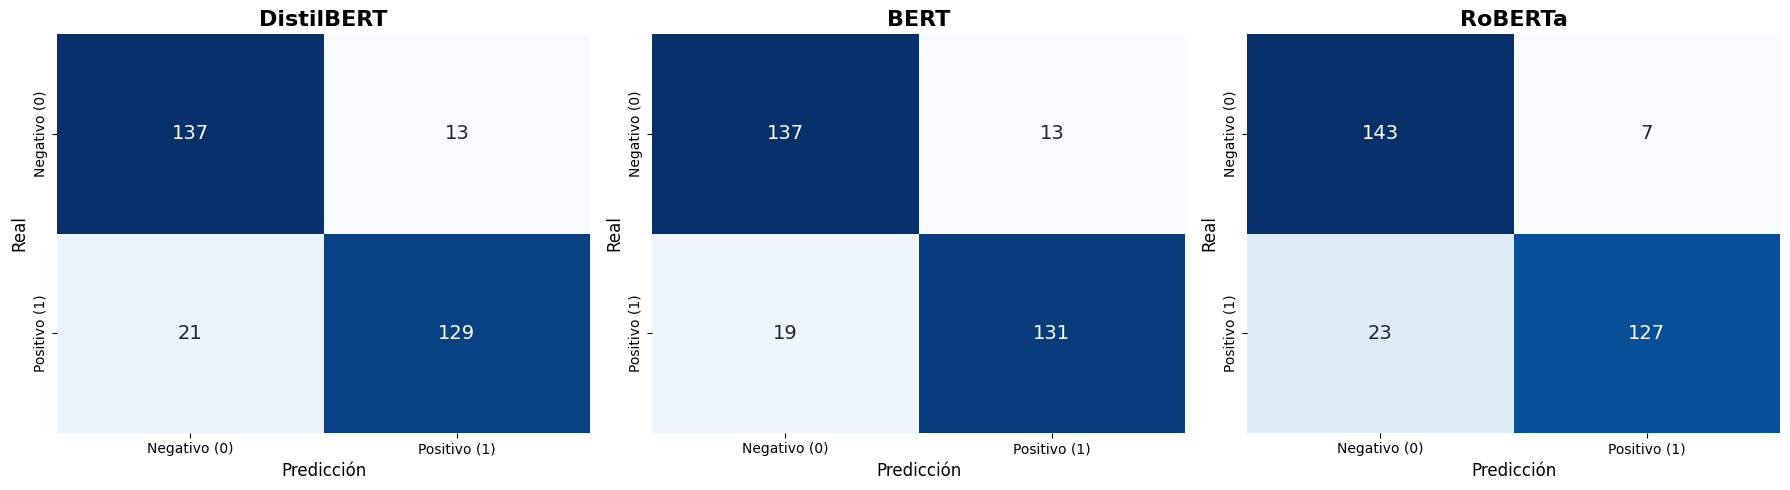

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, result in enumerate(results):
    cm = np.array(result['confusion_matrix'])
    ax = axes[i]

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Negativo (0)', 'Positivo (1)'],
                yticklabels=['Negativo (0)', 'Positivo (1)'], ax=ax, annot_kws={'size': 14})

    ax.set_title(f"{result['name']}", fontsize=16, fontweight='bold')
    ax.set_xlabel('Predicción', fontsize=12)
    ax.set_ylabel('Real', fontsize=12)

plt.tight_layout()
plt.show()

## Conclusiones parciales y decisión
- Comparar F1 y recall antes de escoger el modelo.
- Comprobar umbrales propuestos: F1 ≥ 0.85, recall ≥ 0.85 y latencia ≤ 30 ms/reseña.


In [ ]:
eligible=table[(table.f1>=0.85)&(table.recall>=0.85)&(table.ms_per_review<=30)]
if len(eligible):
    winner=eligible.sort_values(['ms_per_review','f1'],ascending=[True,False]).index[0]
    print('Recomendación según umbrales:',winner)
else: print('Ningún modelo cumple todos los umbrales propuestos; revisar criterios o experimento.')

Recomendación según umbrales: DistilBERT


In [ ]:
import shutil
archive=shutil.make_archive('/content/hf_sentiment_results','zip',ROOT/'results')
try:
 from google.colab import files
 files.download(archive)
except ImportError: print('Archivo local:',archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>